In [1]:
%pip install -q numpy matplotlib scipy > /dev/null
%load_ext autoreload
%autoreload 2

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 80
plt.rcParams["savefig.pad_inches"] = 0.05

import kalman
kalman.set_debug(0)

Note: you may need to restart the kernel to use updated packages.


# Storm Tracking — Physics That Predicts, ML That Elaborates

This notebook tracks a typhoon and a tornado environment, and splits the work between physics and machine learning (ML).

- **Track: physics.** A tropical cyclone is carried by the large-scale wind around it. A small model of that motion forecasts the track, including the turn toward the pole called **recurvature**, and the Kalman covariance gives the cone of uncertainty.
- **Intensity: ML.** How strong the storm gets depends on the sea-surface temperature and the wind shear, which the track model knows nothing about. A small regression learned from past storms fills that gap.

Operational centres split the work the same way: track guidance is dynamical, intensity guidance is statistical.

Both phenomena change regime: a typhoon starts to recurve, a tornado environment switches on. For this we use the Interactive Kalman Filter (IKF), `InteractiveKalmanFilter`, which runs one filter per regime and estimates the probability of each. The literature calls it the Interacting Multiple Model (IMM) filter.

**Roadmap**

1. The reduced typhoon model.
2. Inferring the motion regime from noisy fixes.
3. Physics forecasting: recurvature and the cone of uncertainty.
4. A learned intensity model against persistence, and a landfall probability for Japan.
5. Tornadoes: a regime probability with seasonal priors.
6. Where ML elaborates, and where it must not.

## Step 1 — The Reduced Typhoon Model

The state of `StormModel` is

$$\mathbf{x} = [\text{lon},\ \text{lat},\ v_e,\ v_n,\ I]:$$

the centre position in degrees, the eastward and northward translation speed in km/h, and the intensity $I$ (the maximum sustained wind) in knots. One step is 6 hours, the usual interval between position fixes. In one step:

- the velocity $(v_e, v_n)$ rotates at the turn rate $\omega$ [rad/h]. A storm with $\omega=0$ runs straight; $\omega<0$ (clockwise) is recurvature in the Northern Hemisphere;
- the centre moves with that velocity plus the **beta drift**, a slow drift of about 5 km/h toward the west-northwest that every cyclone has because the Coriolis effect changes with latitude;
- the intensity keeps its value.

The turn makes the model nonlinear, so it is filtered with an Extended Kalman Filter (EKF). The measurement is a **fix**: the longitude and latitude of the centre seen on satellite images, and an intensity estimate.

The cell below runs the model forward from the same start with two turn rates.

state: ['lon', 'lat', 've', 'vn', 'i'] | observed: ['lon', 'lat', 'i']


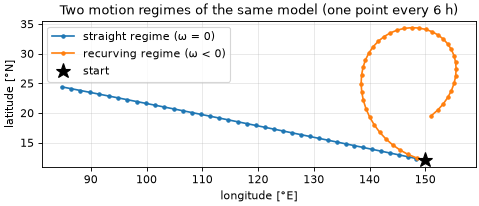

In [2]:
from kalman.apps import StormModel, synthetic_track
from kalman.framework.filters import InteractiveKalmanFilter, ExtendedKalmanFilter

model = StormModel("TC-demo")
print("state:", model.states.keys(), "| observed:", model.observables.keys())

# Start: 150°E, 12°N, moving at 24 km/h west and 4 km/h north, intensity 70 kt
x0 = np.array([[150.], [12.], [-24.], [4.], [70.]])
straight_model = StormModel("straight", omega=0.0)       # turn rate [rad/h]
recurve_model = StormModel("recurve", omega=-0.022)      # clockwise, about 30° per day

def roll(model, x, n=40):
    # Run the model forward n steps (10 days) with no measurements.
    states = [x.ravel()]
    for _ in range(n):
        x = model.f(x)
        states.append(x.ravel())
    return np.array(states)

straight_track = roll(straight_model, x0)
recurve_track = roll(recurve_model, x0)

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(straight_track[:, 0], straight_track[:, 1], "o-", ms=3, label="straight regime (ω = 0)")
ax.plot(recurve_track[:, 0], recurve_track[:, 1], "o-", ms=3, label="recurving regime (ω < 0)")
ax.plot(x0[0], x0[1], "k*", ms=14, label="start")
ax.set_xlabel("longitude [°E]"); ax.set_ylabel("latitude [°N]")
ax.set_aspect(1/np.cos(np.deg2rad(20))); ax.legend(); ax.grid(alpha=0.3)
ax.set_title("Two motion regimes of the same model (one point every 6 h)")
plt.show()

## Step 2 — Inferring the Motion Regime

A storm does not announce its regime; we have to infer it from noisy fixes. The IKF runs one EKF per regime and weighs them by how well each one predicts the incoming fixes. A Markov transition matrix gives the probability of changing regime from one step to the next. The result is a state estimate and a **mode probability** for each regime.

`StormModel.ikf_bank()` builds three regimes (straight, recurve, and stall, a slow and erratic storm) with their transition matrix. The argument `fix_noise` is the standard deviation of a position fix in degrees; 0.3° is about 33 km, typical of a satellite fix. The synthetic storm starts to recurve at cycle 18.

mean position error: IKF 36 km, raw fixes 45 km
mean mode probability after cycle 24: straight 0.37, recurve 0.56, stall 0.08


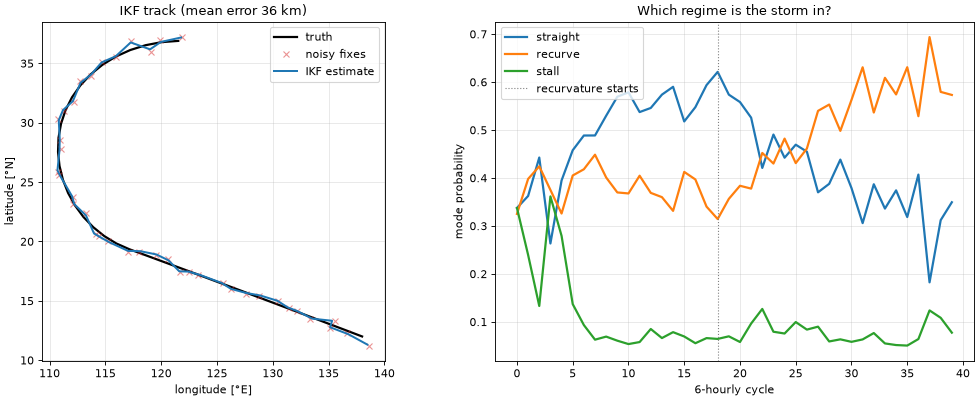

In [3]:
FIX_NOISE = 0.3      # standard deviation of a position fix [deg]

def distance_km(lon, lat, lon_ref, lat_ref):
    # Distance between nearby points [km]. A degree of longitude shrinks with cos(latitude).
    east = (lon - lon_ref) * 111.32 * np.cos(np.deg2rad(lat_ref))
    north = (lat - lat_ref) * 110.57
    return np.hypot(east, north)

truth, fixes = synthetic_track(n_steps=40, recurve_at=18, fix_noise=FIX_NOISE, seed=3)

models, Pi, probs = StormModel.ikf_bank(hemisphere="N", stall=True, fix_noise=FIX_NOISE)
for mm in models:
    # first guess [lon, lat, v_e, v_n, I] and its covariance (variances: deg², (km/h)², kt²)
    mm.initial_state(np.array([[truth[0,0]],[truth[0,1]],[-22.],[6.],[45.]]),
                     np.diag([1.,1.,60.,60.,200.]))
ikf = InteractiveKalmanFilter(models, Pi, probs)
rec = ikf.forward(fixes)
xk = np.asarray(rec.xk)
mu = ikf.mode_probabilities

est_km = np.mean(distance_km(xk[:,0], xk[:,1], truth[:,0], truth[:,1]))
fix_km = np.mean(distance_km(fixes[:,0], fixes[:,1], truth[:,0], truth[:,1]))
print(f"mean position error: IKF {est_km:.0f} km, raw fixes {fix_km:.0f} km")
after = slice(24, None)
print("mean mode probability after cycle 24: " +
      ", ".join(f"{lab} {mu[after, j].mean():.2f}" for j, lab in enumerate(["straight", "recurve", "stall"])))

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(13, 5.2))
ax0.plot(truth[:,0], truth[:,1], "k-", lw=2, label="truth")
ax0.plot(fixes[:,0], fixes[:,1], "x", color="tab:red", ms=5, alpha=0.5, label="noisy fixes")
ax0.plot(xk[:,0], xk[:,1], "-", color="tab:blue", lw=1.8, label="IKF estimate")
ax0.set_xlabel("longitude [°E]"); ax0.set_ylabel("latitude [°N]")
ax0.set_aspect(1/np.cos(np.deg2rad(20))); ax0.legend(); ax0.grid(alpha=0.3)
ax0.set_title(f"IKF track (mean error {est_km:.0f} km)")
for j, lab in enumerate(["straight", "recurve", "stall"]):
    ax1.plot(mu[:, j], lw=2, label=lab)
ax1.axvline(18, color="gray", ls=":", lw=1, label="recurvature starts")
ax1.set_xlabel("6-hourly cycle"); ax1.set_ylabel("mode probability")
ax1.legend(); ax1.grid(alpha=0.3); ax1.set_title("Which regime is the storm in?")
plt.tight_layout(); plt.show()

After the turn the recurve regime becomes the most probable one, but it takes several fixes and never reaches certainty. One fix carries little evidence of a turn: in 6 hours the turn moves the storm less than 10 km away from a straight line, while a fix is uncertain by 33 km. The filtered track is still closer to the truth than the raw fixes.

This IKF is a kinematic tracker: it fits a turn rate because it knows nothing about the wind. Step 3 gives the model the wind field instead.

## Step 3 — Physics Forecasting: Recurvature and the Cone, Without ML

A tropical cyclone is carried by the **steering flow**, the wind around it averaged over the depth of the atmosphere. In the tropics this flow blows from the east. North of the subtropical ridge (at 27°N here) it blows from the west. A storm runs west in the easterlies, drifts north with the beta drift, crosses the ridge and is swept away to the north-east. Recurvature then follows from the wind field, and no turn rate has to be fitted.

`analytic_steering` is an idealised version of this wind field, and `StormModel(steering=...)` uses it in place of the turn rate. The synthetic storm forms at 160°E, 18°N. We assimilate 20 fixes (5 days), then forecast 7 days with no observations. Propagating the covariance along with the state gives the cone of uncertainty.

The argument `q_pos` is the standard deviation, in degrees per step, of the motion the model does not explain. The synthetic storm is pushed around by random eddies of 6 km/h, which is 36 km or about 0.3° in a 6-hour step.

forecast position error at 24 h: 98 km  (predicted standard deviation 111 km)
forecast position error at 48 h: 325 km  (predicted standard deviation 208 km)
forecast position error at 72 h: 477 km  (predicted standard deviation 330 km)


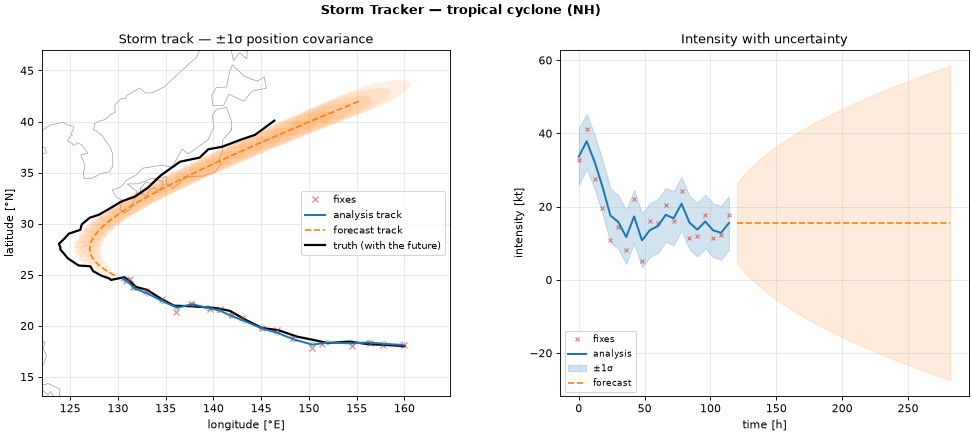

In [4]:
from kalman.apps import synthetic_steered_track, analytic_steering

Q_POS = 0.3          # unexplained motion per 6 h step, standard deviation [deg]

def steer(lon, lat, t=None):
    return analytic_steering(lon, lat, hemisphere="N")       # (v_e, v_n) [km/h]

def physics_tc(track, intensity_fn=None):
    # first guess [lon, lat, v_e, v_n, I] and its covariance (variances: deg², (km/h)², kt²)
    model = StormModel("TC", steering=steer, intensity_fn=intensity_fn, q_pos=Q_POS,
                       fix_noise=FIX_NOISE,
                       x0=np.array([[track[0,0]],[track[0,1]],[-20.],[3.],[35.]]))
    model.initial_state(model.x0, np.diag([0.5,0.5,30,30,100.]))
    return model

def analyse_and_forecast(track, fixes, t_a, steps, intensity_fn=None):
    # Assimilate the first t_a fixes, then forecast `steps` cycles with no observations.
    rec = ExtendedKalmanFilter(physics_tc(track)).forward(fixes[:t_a])
    xa, Pa = np.asarray(rec.xk)[t_a-1].reshape(-1,1), np.asarray(rec.Pk)[t_a-1]
    cone = physics_tc(track, intensity_fn).forecast_cone(xa, Pa, steps=steps)
    return rec, cone

START = dict(lon0=160.0, lat0=18.0)     # where the synthetic storm forms [°E, °N]
truth, fixes = synthetic_steered_track(n_steps=48, fix_noise=FIX_NOISE, seed=7, **START)
t_a = 20
rec, cone = analyse_and_forecast(truth, fixes, t_a, steps=len(truth)-t_a)

# cone[k] is the forecast for cycle t_a + k, a lead time of 6 (k + 1) hours
truth_forecast = truth[t_a:]
lead_km = distance_km(cone["lon"], cone["lat"], truth_forecast[:,0], truth_forecast[:,1])
for hours in (24, 48, 72):
    k = hours // 6 - 1
    print(f"forecast position error at {hours} h: {lead_km[k]:.0f} km  "
          f"(predicted standard deviation {cone['sigma_km'][k]:.0f} km)")

fig = physics_tc(truth).plot(rec, fixes=fixes[:t_a], cone=cone)
fig.axes[0].plot(truth[:,0], truth[:,1], "k-", lw=2, label="truth (with the future)")
fig.axes[0].legend(loc="best", fontsize=9)
plt.show()

The blue track with its ellipses is the analysis, where fixes were assimilated. The orange dashed track with the shaded cone is the forecast. It recurves, although no turn rate was given to the model. For this storm the forecast turns a little east of the truth, and the error at two and three days is about one and a half times the predicted standard deviation.

One storm cannot tell whether the cone has the right width. The next cell repeats the forecast for 40 storms and compares the root-mean-square error with the standard deviation the covariance predicts.

In [5]:
errors, sigmas = [], []
for seed in range(100, 140):
    track, fixes_s = synthetic_steered_track(n_steps=48, fix_noise=FIX_NOISE, seed=seed, **START)
    _, cone_s = analyse_and_forecast(track, fixes_s, t_a, steps=12)
    errors.append(distance_km(cone_s["lon"], cone_s["lat"], track[t_a:t_a+12, 0], track[t_a:t_a+12, 1]))
    sigmas.append(cone_s["sigma_km"])
rms_error = np.sqrt(np.mean(np.square(errors), axis=0))
mean_sigma = np.mean(sigmas, axis=0)
for hours in (24, 48, 72):
    k = hours // 6 - 1
    print(f"{hours} h: RMS error over 40 storms {rms_error[k]:.0f} km, predicted {mean_sigma[k]:.0f} km")

24 h: RMS error over 40 storms 127 km, predicted 107 km
48 h: RMS error over 40 storms 197 km, predicted 184 km
72 h: RMS error over 40 storms 292 km, predicted 292 km


The error grows with the lead time, and the predicted standard deviation stays within about 20% of it. The cone is therefore a usable statement of the forecast uncertainty, and it was obtained from the physics and the filter alone.

## Step 4 — The ML Elaboration: Learned Intensity vs. Persistence

How strong a storm becomes depends on the sea-surface temperature (SST) under it and on the wind shear around it. The track model knows neither, so its intensity forecast is **persistence**: the last value, held.

Operational centres fill this gap with statistics. SHIPS (Statistical Hurricane Intensity Prediction Scheme) is a regression of the intensity change on environmental predictors. `LearnedIntensityModel` is a toy version: a linear regression of the intensity tendency $dI/dt$ on the SST, the shear and the current intensity. We train it on 60 past storms and pass it to the same `StormModel` as `intensity_fn`. The track and the filter are untouched.

For 40 new storms we assimilate 6 fixes, forecast 84 hours with and without the learned model, and compare the intensity errors.

intensity-forecast RMSE reduction from the learned model: mean 88%, from 62% to 99% over 40 storms


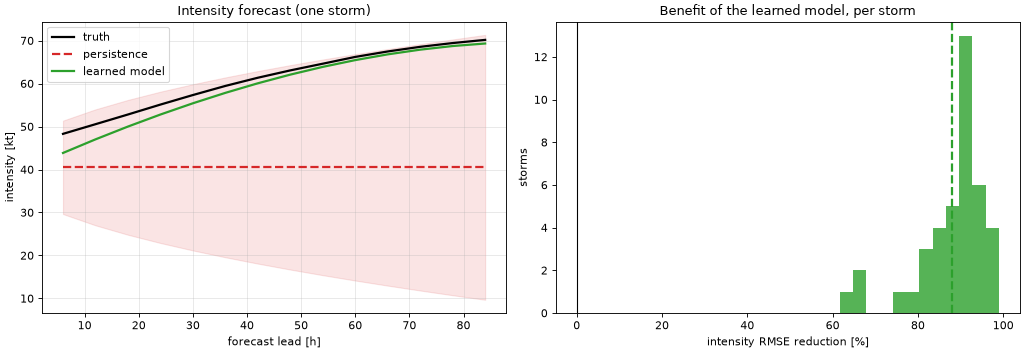

In [6]:
from kalman.apps import LearnedIntensityModel

# Train on 60 past storms with varied starting points and starting intensities [kt]
rng = np.random.default_rng(0)
train_tracks = [synthetic_steered_track(n_steps=48, seed=s, I0=rng.uniform(25,55),
                lat0=rng.uniform(7,13), lon0=rng.uniform(155,172))[0] for s in range(60)]
learned_model = LearnedIntensityModel().fit(train_tracks)

t_a, lead = 6, 14          # 6 fixes assimilated, 14 steps (84 h) forecast
gains, example = [], None
for s in range(200, 240):
    track, fixes_s = synthetic_steered_track(n_steps=48, fix_noise=FIX_NOISE, seed=s)
    _, cone_persistence = analyse_and_forecast(track, fixes_s, t_a, steps=lead)
    _, cone_ml = analyse_and_forecast(track, fixes_s, t_a, steps=lead,
                                      intensity_fn=learned_model.as_intensity_fn())
    truth_intensity = track[t_a:t_a+lead, 4]
    error_persistence = np.sqrt(np.mean((cone_persistence["I"]-truth_intensity)**2))
    error_ml = np.sqrt(np.mean((cone_ml["I"]-truth_intensity)**2))
    gains.append(1 - error_ml/error_persistence)
    if s == 205:
        example = (truth_intensity, cone_persistence["I"], cone_ml["I"], cone_persistence["I_sigma"])
print(f"intensity-forecast RMSE reduction from the learned model: mean {100*np.mean(gains):.0f}%, "
      f"from {100*np.min(gains):.0f}% to {100*np.max(gains):.0f}% over {len(gains)} storms")

truth_I, persistence_I, ml_I, sigma_I = example
hours = (np.arange(lead) + 1) * 6
fig, (ax_intensity, ax_hist) = plt.subplots(1, 2, figsize=(13, 4.6))
ax_intensity.plot(hours, truth_I, "k-", lw=2, label="truth")
ax_intensity.plot(hours, persistence_I, "--", color="tab:red", lw=2, label="persistence")
ax_intensity.fill_between(hours, persistence_I-sigma_I, persistence_I+sigma_I, color="tab:red", alpha=0.12)
ax_intensity.plot(hours, ml_I, "-", color="tab:green", lw=2, label="learned model")
ax_intensity.set_xlabel("forecast lead [h]"); ax_intensity.set_ylabel("intensity [kt]")
ax_intensity.legend(); ax_intensity.grid(alpha=0.3); ax_intensity.set_title("Intensity forecast (one storm)")
ax_hist.hist(np.array(gains)*100, bins=12, color="tab:green", alpha=0.8)
ax_hist.axvline(0, color="k", lw=1)
ax_hist.axvline(np.mean(gains)*100, color="tab:green", ls="--", lw=2)
ax_hist.set_xlabel("intensity RMSE reduction [%]"); ax_hist.set_ylabel("storms")
ax_hist.set_title("Benefit of the learned model, per storm")
plt.tight_layout(); plt.show()

Persistence holds the intensity flat and misses the intensification. The learned model follows it, and removes most of the error for every test storm.

The test is easier than reality: the synthetic intensity law is linear in the three predictors, so the regression can recover it almost exactly. The error that remains comes mainly from the uncertain starting intensity. What carries over to a real system is the arrangement: the learned part is confined to one quantity and tested on storms it has not seen, and the physics keeps the track and the covariance.

## Step 4b — Case Study: A Typhoon Threatening Japan

The typhoons that reach Japan are the recurving ones: they form in the tropics, run west-northwest, then turn north-east toward Honshu, Japan's main island. The model is the one of Step 3 with a Northwest-Pacific wind field, `japan_steering`.

What an emergency manager needs is the **probability of landfall**. We draw 400 states from the filter's covariance, run each one through the dynamics (`ensemble_forecast`), and count the fraction of tracks that cross the Japanese coastline (`landfall_probability`).

We look at two storms, one that strikes Japan and one that recurves out to sea, and then at how the probability changes as fixes arrive.

strikes Japan: P(landfall in Japan) = 72%


recurves out to sea: P(landfall in Japan) = 0%


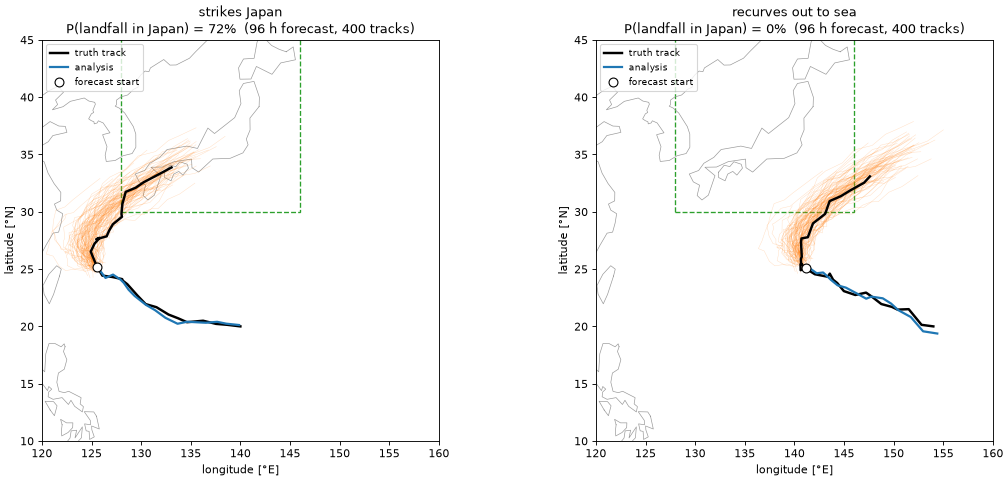

In [7]:
from kalman.apps import (synthetic_steered_track, japan_steering, japan_region,
                         landfall_probability, JAPAN_BBOX)
from kalman.apps.weather import earth_geometry

def japan_tc(x0):
    m = StormModel("JP", steering=japan_steering, q_pos=Q_POS, fix_noise=FIX_NOISE, x0=x0)
    m.initial_state(x0, np.diag([0.5,0.5,30,30,100.]))
    return m

scenarios = {"strikes Japan": dict(lon0=140, lat0=20, seed=7),
             "recurves out to sea": dict(lon0=154, lat0=20, seed=3)}

fig, axes = plt.subplots(1, 2, figsize=(14, 6.2))
lo0, lo1, la0, la1 = JAPAN_BBOX
for ax, (name, cfg) in zip(axes, scenarios.items()):
    truth, fixes = synthetic_steered_track(n_steps=32, I0=75, steering=japan_steering,
                                           eddy=6.0, fix_noise=FIX_NOISE, **cfg)
    x0 = np.array([[truth[0,0]],[truth[0,1]],[-14.],[6.],[75.]])
    t_a = 16
    rec = ExtendedKalmanFilter(japan_tc(x0)).forward(fixes[:t_a])
    xa, Pa = np.asarray(rec.xk)[t_a-1].reshape(-1,1), np.asarray(rec.Pk)[t_a-1]
    ens = japan_tc(x0).ensemble_forecast(xa, Pa, steps=32-t_a, n_samples=400, seed=2)
    prob, hit = landfall_probability(ens)
    print(f"{name}: P(landfall in Japan) = {100*prob:.0f}%")

    for seg in earth_geometry("coastline"):
        ax.plot(seg[:,0], seg[:,1], color="0.6", lw=0.6)
    ax.add_patch(plt.Rectangle((lo0, la0), lo1-lo0, la1-la0, fill=False, ec="tab:green", ls="--", lw=1.2))
    for tr in ens[::4]:                                   # every 4th forecast track
        ax.plot(tr[:,0], tr[:,1], "-", color="tab:orange", lw=0.4, alpha=0.25)
    ax.plot(truth[:,0], truth[:,1], "k-", lw=2.2, label="truth track")
    ax.plot(np.asarray(rec.xk)[:,0], np.asarray(rec.xk)[:,1], "-", color="tab:blue", lw=2, label="analysis")
    ax.plot(truth[t_a-1,0], truth[t_a-1,1], "wo", mec="k", ms=8, label="forecast start")
    ax.set_xlim(120, 160); ax.set_ylim(10, 45)
    ax.set_aspect(1/np.cos(np.deg2rad(30)))
    ax.set_xlabel("longitude [°E]"); ax.set_ylabel("latitude [°N]")
    ax.legend(loc="upper left", fontsize=8)
    ax.set_title(f"{name}\nP(landfall in Japan) = {100*prob:.0f}%  (96 h forecast, 400 tracks)")
plt.tight_layout(); plt.show()

lead time [h]   : [144, 132, 120, 108, 96, 84, 72, 60, 48]
P(landfall) [%] : [34, 55, 80, 82, 72, 91, 96, 93, 92]
the true storm makes landfall: True


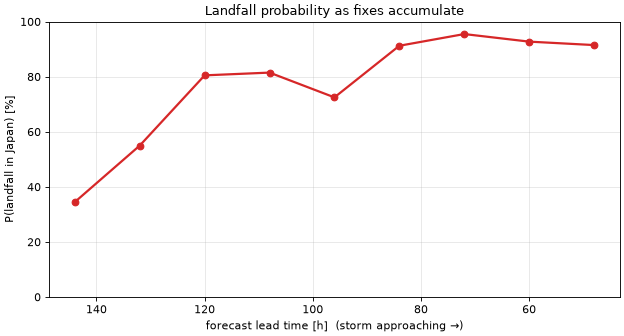

In [8]:
# The landfall probability as the storm approaches and fixes accumulate
truth, fixes = synthetic_steered_track(n_steps=32, lon0=140, lat0=20, I0=75, steering=japan_steering,
                                       eddy=6.0, fix_noise=FIX_NOISE, seed=7)
x0 = np.array([[truth[0,0]],[truth[0,1]],[-14.],[6.],[75.]])
leads, probs = [], []
for t_a in range(8, 26, 2):
    rec = ExtendedKalmanFilter(japan_tc(x0)).forward(fixes[:t_a])
    xa, Pa = np.asarray(rec.xk)[t_a-1].reshape(-1,1), np.asarray(rec.Pk)[t_a-1]
    ens = japan_tc(x0).ensemble_forecast(xa, Pa, steps=32-t_a, n_samples=400, seed=2)
    leads.append((32-t_a)*6); probs.append(100*landfall_probability(ens)[0])
print("lead time [h]   :", leads)
print("P(landfall) [%] :", [round(p) for p in probs])
print("the true storm makes landfall:", bool(japan_region(truth[:,0], truth[:,1]).any()))

fig, ax = plt.subplots(figsize=(8, 4.4))
ax.plot(leads, probs, "o-", color="tab:red", lw=2)
ax.invert_xaxis(); ax.set_ylim(0, 100)
ax.set_xlabel("forecast lead time [h]  (storm approaching →)"); ax.set_ylabel("P(landfall in Japan) [%]")
ax.grid(alpha=0.3); ax.set_title("Landfall probability as fixes accumulate")
plt.tight_layout(); plt.show()

For the first storm most of the 400 forecast tracks cross the Japanese coast; for the second none do. As the first storm approaches, its landfall probability rises from about one in three, six days ahead, to above 90% in the last three days. The rise is not steady, because each new fix moves the analysis a little.

The cone of Step 3 and this probability are two readings of the same forecast distribution. Both come from the dynamics and the Kalman covariance.

## Step 5 — Tornadoes: Regime Probability with Seasonal Priors

A tornado is too small and too short-lived to track: it can be predicted only minutes ahead. What can be estimated is whether the environment favours tornadoes. Forecasters summarise this with the **significant tornado parameter** (STP), a dimensionless index built from the instability of the air and the wind shear. Values above 1 favour strong tornadoes.

`TornadoEnvironmentModel` has one state, the STP, which relaxes toward the mean of its regime: 0.3 in the benign regime and 3 in the tornadic one. An IKF over the two regimes gives the probability that the environment is tornadic.

The season enters through the transition matrix. In the peak season `ikf_bank(season=...)` makes a switch into the tornadic regime more likely and the regime longer-lived. We filter the same hourly observations with the peak-season and the off-season matrix.

season='peak': mean P(tornadic) inside the true windows 0.86, outside 0.21
season='off': mean P(tornadic) inside the true windows 0.56, outside 0.02


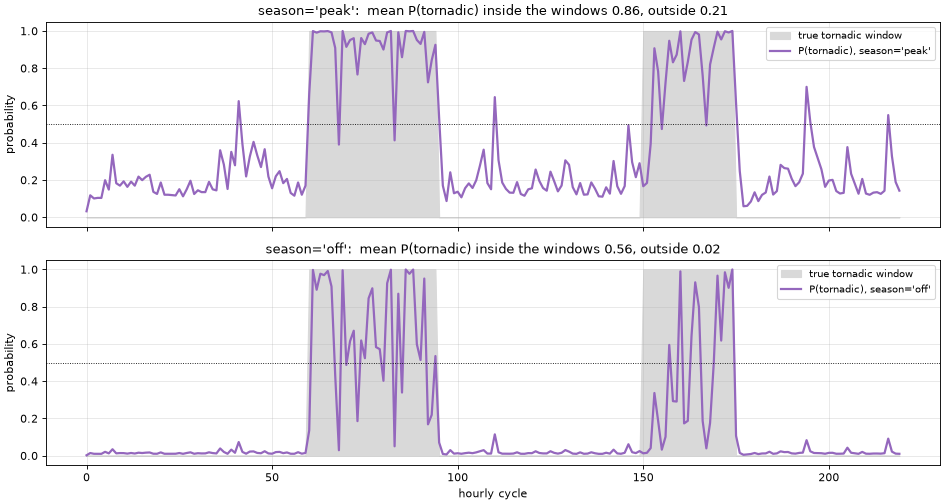

peak-season transition matrix (per hour):
 [[0.9  0.1 ]
 [0.15 0.85]]
off-season transition matrix (per hour):
 [[0.985 0.015]
 [0.7   0.3  ]]


In [9]:
from kalman.apps import TornadoEnvironmentModel, synthetic_environment

obs, labels = synthetic_environment(n_steps=220, onsets=((60,95),(150,175)), seed=4)

fig, axes = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True)
for season, ax in zip(["peak", "off"], axes):
    models, Pi, p0 = TornadoEnvironmentModel.ikf_bank(season=season)
    ikf = InteractiveKalmanFilter(models, Pi, p0)
    ikf.forward(obs)
    p_tor = ikf.mode_probabilities[:, 1]
    ax.fill_between(np.arange(len(labels)), 0, labels, color="0.85", label="true tornadic window")
    ax.plot(p_tor, color="tab:purple", lw=2, label=f"P(tornadic), season='{season}'")
    ax.axhline(0.5, color="k", ls=":", lw=0.8)
    inside = p_tor[labels==1].mean(); outside = p_tor[labels==0].mean()
    ax.set_ylabel("probability"); ax.legend(loc="upper right", fontsize=9); ax.grid(alpha=0.3)
    ax.set_title(f"season='{season}':  mean P(tornadic) inside the windows {inside:.2f}, outside {outside:.2f}")
    print(f"season='{season}': mean P(tornadic) inside the true windows {inside:.2f}, outside {outside:.2f}")
axes[1].set_xlabel("hourly cycle")
plt.tight_layout(); plt.show()

_, pi_peak, _ = TornadoEnvironmentModel.ikf_bank(season="peak")
_, pi_off, _ = TornadoEnvironmentModel.ikf_bank(season="off")
print("peak-season transition matrix (per hour):\n", pi_peak.round(3))
print("off-season transition matrix (per hour):\n", pi_off.round(3))

Row $i$, column $j$ of a transition matrix is the probability of going from regime $i$ to regime $j$ in one hour (0 is benign, 1 is tornadic).

With the peak-season matrix the filter enters the tornadic regime quickly and stays in it. With the off-season matrix the regime is rare and short-lived, so the same observations raise the probability less, and there are fewer false alarms outside the true windows. This is how climatology enters a nowcast (a forecast for the next few hours): as a prior on regime changes, in place of a hand-tuned threshold.

The peak-season matrix describes a very active period: in the long run it puts the environment in the tornadic regime 40% of the time.

## Step 6 — Where ML Elaborates, and Where It Must Not

| Component | Done by | Why |
|---|---|---|
| Track | Physics: steering flow and beta drift | The dynamics hold for storms never seen before, and the covariance gives the cone. |
| Regime and season | IKF transition matrix | A prior whose meaning is clear. |
| Intensity | ML: a regression on SST and shear | It depends on quantities outside the track dynamics. |

In each case a physical estimator carries the state and its uncertainty, and the learned part is confined to one quantity that can be tested on storms it has not seen. Because the forecast runs with and without the learned part, its value can be measured, as in Step 4.